<a href="https://colab.research.google.com/github/james-mawuena/credit-card-fraud-detection/blob/main/credit_card_fraud_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
from sklearn.datasets import fetch_openml

data = fetch_openml(data_id=1597, as_frame=True)
df = data.frame
df["Class"] = df["Class"].astype(int)

print(df.shape)
print(df["Class"].value_counts())
df.head()

(284807, 30)
Class
0    284315
1       492
Name: count, dtype: int64


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="Class")
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training transactions:", len(y_train), "| frauds:", y_train.sum())
print("Test transactions:", len(y_test), "| frauds:", y_test.sum())

Training transactions: 227845 | frauds: 394
Test transactions: 56962 | frauds: 98


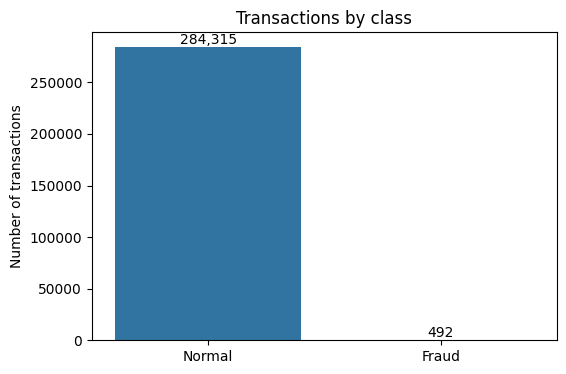

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=["Normal", "Fraud"], y=counts.values)
ax.bar_label(ax.containers[0], labels=[f"{v:,}" for v in counts.values])
plt.title("Transactions by class")
plt.ylabel("Number of transactions")
plt.show()

In [5]:
from sklearn.metrics import accuracy_score, recall_score

lazy = [0] * len(y_test)

print("Lazy guess accuracy:", round(accuracy_score(y_test, lazy), 4))
print("Frauds caught (recall):", recall_score(y_test, lazy))

Lazy guess accuracy: 0.9983
Frauds caught (recall): 0.0


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train["Amount"] = scaler.fit_transform(X_train[["Amount"]])
X_test["Amount"] = scaler.transform(X_test[["Amount"]])

print(X_train["Amount"].describe().round(2))

count    227845.00
mean         -0.00
std           1.00
min          -0.35
25%          -0.33
50%          -0.26
75%          -0.04
max         102.12
Name: Amount, dtype: float64


## Logistic Regression

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score

log = LogisticRegression(max_iter=1000)
log.fit(X_train, y_train)
pred = log.predict(X_test)

print(confusion_matrix(y_test, pred))
print("Recall (frauds caught):", round(recall_score(y_test, pred), 3))
print("Precision (flags that were real fraud):", round(precision_score(y_test, pred), 3))

[[56851    13]
 [   35    63]]
Recall (frauds caught): 0.643
Precision (flags that were real fraud): 0.829


In [8]:
log_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
log_bal.fit(X_train, y_train)
pred_bal = log_bal.predict(X_test)

print(confusion_matrix(y_test, pred_bal))
print("Recall (frauds caught):", round(recall_score(y_test, pred_bal), 3))
print("Precision (flags that were real fraud):", round(precision_score(y_test, pred_bal), 3))

[[55425  1439]
 [    8    90]]
Recall (frauds caught): 0.918
Precision (flags that were real fraud): 0.059


## Neural Network

In [9]:
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

nn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
nn.compile(loss="binary_crossentropy", optimizer="adam")

n_normal = (y_train == 0).sum()
n_fraud = (y_train == 1).sum()
weights = {
    0: len(y_train) / (2 * n_normal),
    1: len(y_train) / (2 * n_fraud),
}

nn.fit(X_train, y_train, epochs=10, batch_size=2048,
       class_weight=weights, verbose=0)

pred_nn = (nn.predict(X_test, verbose=0).ravel() > 0.5).astype(int)

print(confusion_matrix(y_test, pred_nn))
print("Recall (frauds caught):", round(recall_score(y_test, pred_nn), 3))
print("Precision (flags that were real fraud):", round(precision_score(y_test, pred_nn), 3))

[[55747  1117]
 [    9    89]]
Recall (frauds caught): 0.908
Precision (flags that were real fraud): 0.074


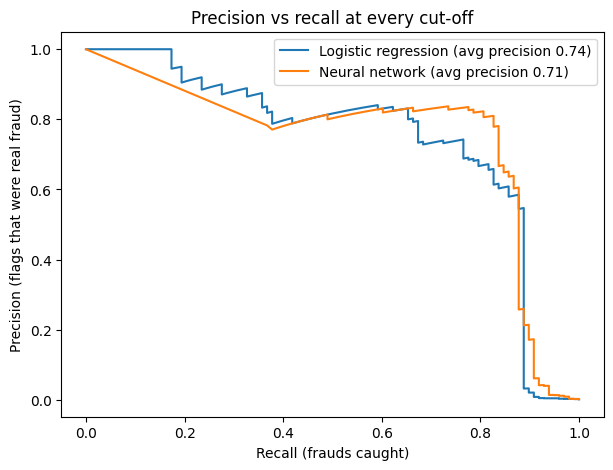

In [10]:
from sklearn.metrics import precision_recall_curve, average_precision_score

scores = {
    "Logistic regression": log.predict_proba(X_test)[:, 1],
    "Neural network": nn.predict(X_test, verbose=0).ravel(),
}

plt.figure(figsize=(7, 5))
for name, s in scores.items():
    precision, recall, _ = precision_recall_curve(y_test, s)
    ap = average_precision_score(y_test, s)
    plt.plot(recall, precision, label=f"{name} (avg precision {ap:.2f})")

plt.xlabel("Recall (frauds caught)")
plt.ylabel("Precision (flags that were real fraud)")
plt.title("Precision vs recall at every cut-off")
plt.legend()
plt.show()

In [11]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)

print("Fit group:", len(y_fit), "| frauds:", y_fit.sum())
print("Validation group:", len(y_val), "| frauds:", y_val.sum())
print("Test group (untouched):", len(y_test), "| frauds:", y_test.sum())

Fit group: 170883 | frauds: 295
Validation group: 56962 | frauds: 99
Test group (untouched): 56962 | frauds: 98


## Logistic Regression with training, validation and test set

In [12]:
import numpy as np
from sklearn.metrics import precision_recall_curve

log2 = LogisticRegression(max_iter=1000)
log2.fit(X_fit, y_fit)

val_scores = log2.predict_proba(X_val)[:, 1]
precision, recall, cutoffs = precision_recall_curve(y_val, val_scores)
precision, recall = precision[:-1], recall[:-1]

ok = np.where(precision >= 0.5)[0]
best = ok[np.argmax(recall[ok])]
cutoff = cutoffs[best]

print("Chosen cut-off:", round(cutoff, 3))
print("Validation recall:", round(recall[best], 3))
print("Validation precision:", round(precision[best], 3))

Chosen cut-off: 0.013
Validation recall: 0.808
Validation precision: 0.5


In [13]:
test_scores = log2.predict_proba(X_test)[:, 1]
pred_cut = (test_scores >= cutoff).astype(int)

print(confusion_matrix(y_test, pred_cut))
print("Recall (frauds caught):", round(recall_score(y_test, pred_cut), 3))
print("Precision (flags that were real fraud):", round(precision_score(y_test, pred_cut), 3))

[[56762   102]
 [   12    86]]
Recall (frauds caught): 0.878
Precision (flags that were real fraud): 0.457


In [14]:
tf.keras.utils.set_random_seed(42)

nn2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_fit.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
nn2.compile(loss="binary_crossentropy", optimizer="adam")

n_normal = (y_fit == 0).sum()
n_fraud = (y_fit == 1).sum()
weights2 = {
    0: len(y_fit) / (2 * n_normal),
    1: len(y_fit) / (2 * n_fraud),
}
nn2.fit(X_fit, y_fit, epochs=10, batch_size=2048,
        class_weight=weights2, verbose=0)

val_nn = nn2.predict(X_val, verbose=0).ravel()
precision, recall, cutoffs = precision_recall_curve(y_val, val_nn)
precision, recall = precision[:-1], recall[:-1]
ok = np.where(precision >= 0.5)[0]
best = ok[np.argmax(recall[ok])]
cutoff_nn = cutoffs[best]

print("Chosen cut-off:", round(cutoff_nn, 3))
print("Validation recall:", round(recall[best], 3))
print("Validation precision:", round(precision[best], 3))

test_nn = nn2.predict(X_test, verbose=0).ravel()
pred_nn_cut = (test_nn >= cutoff_nn).astype(int)
print(confusion_matrix(y_test, pred_nn_cut))
print("Test recall:", round(recall_score(y_test, pred_nn_cut), 3))
print("Test precision:", round(precision_score(y_test, pred_nn_cut), 3))

Chosen cut-off: 0.922
Validation recall: 0.838
Validation precision: 0.5
[[56763   101]
 [   12    86]]
Test recall: 0.878
Test precision: 0.46


In [15]:
from sklearn.metrics import average_precision_score

results = []
for lr in [0.0001, 0.001, 0.01, 0.1]:
    tf.keras.utils.set_random_seed(42)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_fit.shape[1],)),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(loss="binary_crossentropy",
                  optimizer=tf.keras.optimizers.Adam(learning_rate=lr))
    history = model.fit(X_fit, y_fit, epochs=10, batch_size=2048,
                        class_weight=weights2, verbose=0)
    v_scores = model.predict(X_val, verbose=0).ravel()
    results.append({
        "Learning rate": lr,
        "Final training loss": round(history.history["loss"][-1], 4),
        "Validation avg precision": round(average_precision_score(y_val, v_scores), 3),
    })

pd.DataFrame(results)

,Learning rate,Final training loss,Validation avg precision
0,0.0001,0.2674,0.572
1,0.0010,0.0769,0.693
2,0.0100,0.0395,0.689
3,0.1000,0.2157,0.644


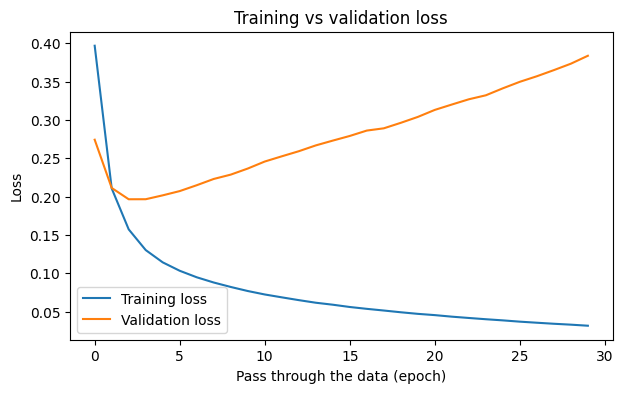

In [16]:
tf.keras.utils.set_random_seed(42)

curve_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_fit.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
curve_model.compile(loss="binary_crossentropy",
                    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001))

val_weights = y_val.map(weights2).values

history = curve_model.fit(
    X_fit, y_fit, epochs=30, batch_size=2048,
    class_weight=weights2,
    validation_data=(X_val, y_val, val_weights),
    verbose=0,
)

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Pass through the data (epoch)")
plt.ylabel("Loss")
plt.title("Training vs validation loss")
plt.legend()
plt.show()

In [17]:
tf.keras.utils.set_random_seed(42)

es_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_fit.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
es_model.compile(loss="binary_crossentropy",
                 optimizer=tf.keras.optimizers.Adam(learning_rate=0.001))

early = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history = es_model.fit(
    X_fit, y_fit, epochs=30, batch_size=2048,
    class_weight=weights2,
    validation_data=(X_val, y_val, val_weights),
    callbacks=[early], verbose=0,
)

print("Training stopped after pass:", len(history.history["loss"]))
print("Best pass:", int(np.argmin(history.history["val_loss"])) + 1)

v_scores = es_model.predict(X_val, verbose=0).ravel()
print("Validation avg precision:", round(average_precision_score(y_val, v_scores), 3))

Training stopped after pass: 6
Best pass: 3
Validation avg precision: 0.683


## Decision Tree, Random Forest and XGBoost

In [18]:
from sklearn.tree import DecisionTreeClassifier

def evaluate(name, val_scores, test_scores):
    precision, recall, cutoffs = precision_recall_curve(y_val, val_scores)
    precision, recall = precision[:-1], recall[:-1]
    ok = np.where(precision >= 0.5)[0]
    best = ok[np.argmax(recall[ok])]
    cut = cutoffs[best]
    pred = (test_scores >= cut).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"Model": name, "Cut-off": round(cut, 3), "Caught": tp,
            "Missed": fn, "False alarms": fp,
            "Recall": round(tp / (tp + fn), 3),
            "Precision": round(tp / (tp + fp), 3)}

tree = DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42)
tree.fit(X_fit, y_fit)

rows = [
    evaluate("Logistic regression",
             log2.predict_proba(X_val)[:, 1], log2.predict_proba(X_test)[:, 1]),
    evaluate("Neural network",
             nn2.predict(X_val, verbose=0).ravel(), nn2.predict(X_test, verbose=0).ravel()),
    evaluate("Decision tree",
             tree.predict_proba(X_val)[:, 1], tree.predict_proba(X_test)[:, 1]),
]

pd.DataFrame(rows)

,Model,Cut-off,Caught,Missed,False alarms,Recall,Precision
0,Logistic regression,0.013,86,12,102,0.878,0.457
1,Neural network,0.922,86,12,101,0.878,0.460
2,Decision tree,0.986,79,19,81,0.806,0.494


In [19]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(
    n_estimators=100, max_depth=8,
    class_weight="balanced_subsample", n_jobs=-1, random_state=42
)
forest.fit(X_fit, y_fit)

rows.append(
    evaluate("Random forest",
             forest.predict_proba(X_val)[:, 1], forest.predict_proba(X_test)[:, 1])
)

pd.DataFrame(rows)

,Model,Cut-off,Caught,Missed,False alarms,Recall,Precision
0,Logistic regression,0.013,86,12,102,0.878,0.457
1,Neural network,0.922,86,12,101,0.878,0.460
2,Decision tree,0.986,79,19,81,0.806,0.494
3,Random forest,0.295,84,14,109,0.857,0.435


In [20]:
from xgboost import XGBClassifier

n_normal = (y_fit == 0).sum()
n_fraud = (y_fit == 1).sum()

xgb = XGBClassifier(
    n_estimators=500, learning_rate=0.1, max_depth=4,
    scale_pos_weight=n_normal / n_fraud,
    eval_metric="aucpr", early_stopping_rounds=20,
    n_jobs=-1, random_state=42,
)
xgb.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)

print("Best tree:", xgb.best_iteration)

rows.append(
    evaluate("XGBoost",
             xgb.predict_proba(X_val)[:, 1], xgb.predict_proba(X_test)[:, 1])
)

pd.DataFrame(rows)

Best tree: 29


,Model,Cut-off,Caught,Missed,False alarms,Recall,Precision
0,Logistic regression,0.013,86,12,102,0.878,0.457
1,Neural network,0.922,86,12,101,0.878,0.460
2,Decision tree,0.986,79,19,81,0.806,0.494
3,Random forest,0.295,84,14,109,0.857,0.435
4,XGBoost,0.702,85,13,113,0.867,0.429


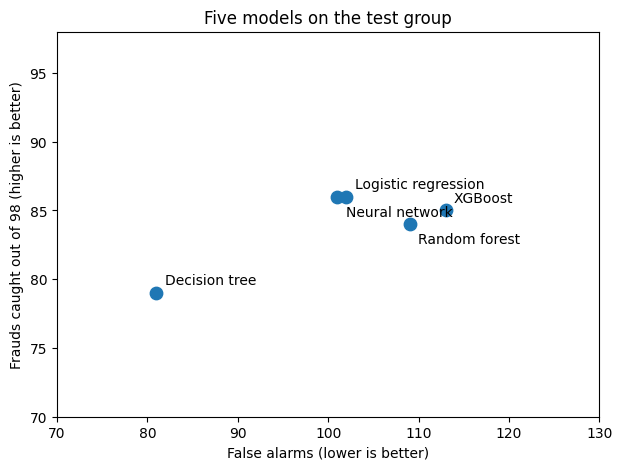

In [21]:
results = pd.DataFrame(rows)

plt.figure(figsize=(7, 5))
plt.scatter(results["False alarms"], results["Caught"], s=80)
for i, r in results.iterrows():
    dy = 6 if i % 2 == 0 else -14
    plt.annotate(r["Model"], (r["False alarms"], r["Caught"]),
                 textcoords="offset points", xytext=(6, dy))

plt.xlim(70, 130)
plt.ylim(70, 98)
plt.xlabel("False alarms (lower is better)")
plt.ylabel("Frauds caught out of 98 (higher is better)")
plt.title("Five models on the test group")
plt.show()

In [24]:
def run_once(seed):
    X_all = df.drop(columns="Class")
    y_all = df["Class"]

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_all, y_all, test_size=0.2, random_state=seed, stratify=y_all)
    X_f, X_v, y_f, y_v = train_test_split(
        X_tr, y_tr, test_size=0.25, random_state=seed, stratify=y_tr)

    X_f, X_v, X_te = X_f.copy(), X_v.copy(), X_te.copy()
    sc = StandardScaler().fit(X_f[["Amount"]])
    for part in (X_f, X_v, X_te):
        part["Amount"] = sc.transform(part[["Amount"]])

    models = {
        "Logistic regression": LogisticRegression(max_iter=1000),
        "Decision tree": DecisionTreeClassifier(
            max_depth=6, class_weight="balanced", random_state=42),
    }
    out = {"Seed": seed}
    for name, m in models.items():
        m.fit(X_f, y_f)
        precision, recall, cutoffs = precision_recall_curve(
            y_v, m.predict_proba(X_v)[:, 1])
        precision, recall = precision[:-1], recall[:-1]
        ok = np.where(precision >= 0.5)[0]
        if len(ok) > 0:
            best = ok[np.argmax(recall[ok])]
        else:
            f1 = 2 * precision * recall / (precision + recall + 1e-12)
            best = np.argmax(f1)
        cut = cutoffs[best]
        out[name + ": rule met"] = len(ok) > 0
        pred = (m.predict_proba(X_te)[:, 1] >= cut).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
        out[name + ": caught"] = tp
        out[name + ": false alarms"] = fp
    return out

repeat = pd.DataFrame([run_once(s) for s in [1, 2, 3, 4, 5]]).set_index("Seed")
repeat.loc["Average"] = repeat.astype(float).mean().round(2)
repeat

,Logistic regression: rule met,Logistic regression: caught,Logistic regression: false alarms,Decision tree: rule met,Decision tree: caught,Decision tree: false alarms
Seed,,,,,,
1,1.0,87.0,87.0,1.0,83.0,70.0
2,1.0,86.0,80.0,1.0,80.0,26.0
3,1.0,88.0,100.0,0.0,83.0,115.0
4,1.0,83.0,88.0,1.0,80.0,54.0
5,1.0,84.0,63.0,0.0,74.0,82.0
Average,1.0,85.6,83.6,0.6,80.0,69.4
